# 03 · Đánh giá AEGIS: ablation, kiểm định ý nghĩa, phân tích trọng số gating

Thay cho các lệnh `select_fusion`, `ablation`, `significance`, `weights_analysis`, `export` trong README.
Mọi thứ được fit trên `val_gating_fit`; `test_benchmark` và các pool S4 chỉ được đọc **một lần** trong ablation.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

from src.core.config import load_config
from src.core.contracts import SplitManifest

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
cfg = load_config()
print("repo:", ROOT)

repo: c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics


In [2]:
# Bộ dữ liệu thật (GenImage đã chuẩn hoá). Nếu chưa có, notebook tự chuyển sang DEMO MODE:
# ảnh tổng hợp + embedding giả lập, chạy trên CPU trong ~1 phút. Số liệu DEMO không có ý nghĩa khoa học.
MANIFEST = ROOT / "data/normalized_v2/manifest.json"
DEMO = not MANIFEST.exists()
if DEMO:
    from src.models.demo_features import build_demo
    cfg, man = build_demo(ROOT / "data/demo", scale=6, cfg=cfg)
    MANIFEST = ROOT / "data/demo/images/manifest.json"
else:
    man = SplitManifest.load(MANIFEST)
print("DEMO MODE" if DEMO else "REAL DATA", "|", len(man.records), "records |", MANIFEST)

REAL DATA | 32170 records | c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\normalized_v2\manifest.json


In [3]:
HEAD_VARIANTS = ["clean", "aug"]
OUT = ROOT / ("reports/demo_v3" if DEMO else "reports/v3")
S4_SEEDS = [0, 1] if DEMO else [0, 1, 2, 3, 4]
B = 300 if DEMO else 2000
if DEMO:
    cfg["fewshot"]["n_values"] = [5, 20]     # demo S4 support pool is too small for N = 100
OUT.mkdir(parents=True, exist_ok=True)

## 1. Chọn kiểu fusion (chỉ dùng val_gating_fit / val_gating_verify)

In [4]:
from src.evaluation import select_fusion
sel = select_fusion.run(cfg, HEAD_VARIANTS, OUT / "fusion_selection", manifest=MANIFEST, B=B)
print("fusion được chọn:", sel["selected"])
cfg.setdefault("gating", {})["fusion"] = sel["selected"]

2026-11-22 18:25:04,589 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-22 18:25:04,612 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_verify.pt (n=1440)
2026-11-22 18:25:04,880 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 2.3774, 'dinov2': 1.7704, 'freq': 6.4604}
2026-11-22 18:25:08,343 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.4706 -> 0.3733
2026-11-22 18:25:08,357 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 2.3774, 'dinov2': 1.7704, 'freq': 6.4604}
2026-11-22 18:25:09,691 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.4464 -> 0.3680
2026-11-22 18:25:09,757 | WARNING | aegis.src.evaluation.select_fusion | fusion selection: slice jpeg has too few samples/classes (n=0); skipped
2026-11-22 18:25:09,758 | WARNING | aegis.src.evaluation.select_fusion | fusion selection: slice blur has too few samples/classes (n=0); s

fusion được chọn: prob


## 2. Bảng ablation chính (S1 sạch · S2 JPEG · S3 blur/resize · S4 generator chưa thấy)

In [5]:
from src.evaluation.ablation import run_all
rows = run_all(cfg, HEAD_VARIANTS, OUT, s4_seeds=S4_SEEDS, save_predictions=True)
abl = pd.DataFrame(rows)
full = abl[(abl.variant == "full") & (abl.level.isin(["clean", "all"])) & (abl.N.isna() | (abl.N == 20))]
display(full.pivot_table(index=["head_variant", "method"], columns=["scenario", "generator"], values="auroc"))

2026-11-22 18:25:13,506 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-22 18:25:13,602 | INFO    | aegis.src.learning.bundle_io | loaded bundle test_benchmark.pt (n=11200)
2026-11-22 18:25:13,628 | INFO    | aegis.src.learning.bundle_io | loaded bundle s4_support.pt (n=1600)
2026-11-22 18:25:13,678 | INFO    | aegis.src.learning.bundle_io | loaded bundle s4_eval.pt (n=6256)
2026-11-22 18:25:13,683 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 2.3774, 'dinov2': 1.7704, 'freq': 6.4604}
2026-11-22 18:25:15,322 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.4706 -> 0.3733
2026-11-22 18:25:15,764 | WARNING | aegis.src.learning.fewshot | few-shot data scarcity: N=5 < 10; keeping gating weights unchanged (alpha=0)
2026-11-22 18:25:15,781 | WARNING | aegis.src.learning.fewshot | few-shot data scarcity: N=5 < 10; keeping gating weights unchanged (alpha=0)
2026-11-22 18:25:15,798 | WARNING | aegis.src

scenario                                S4                  
generator                              all midjourney   vqdm
head_variant method                                         
aug          aegis                   0.967      0.932  0.999
             clip                    0.961      0.928  0.995
             dinov2                  0.854      0.783  0.923
             freq                    0.874      0.774  0.975
             naive_avg               0.957      0.914  0.998
             quality_only            0.624      0.654  0.593
             static_learned_support  0.958      0.916  0.998
             static_lr               0.957      0.916  0.998
clean        aegis                   0.982      0.965  0.999
             clip                    0.979      0.961  0.997
             dinov2                  0.874      0.802  0.944
             freq                    0.909      0.829  0.991
             naive_avg               0.976      0.952  0.999
             quality_only            0.624      0.654  0.593
             static_learned_support  0.972      0.946  0.998
             static_lr               0.972      0.946  0.998

## 3. Kiểm định bootstrap ghép cặp (theo ảnh gốc): AEGIS so với từng baseline

In [6]:
from src.evaluation import significance
sig = pd.DataFrame(significance.run(OUT / "predictions", OUT, B=B, manifest=MANIFEST, cfg=cfg))
pooled = sig[(sig.metric == "auroc") & sig.level.isin(["clean", "all"])]
display(pooled[["head_variant", "scenario", "generator", "N", "baseline", "delta", "ci_lo", "ci_hi", "significant"]]
        .head(40))

2026-11-22 18:32:06,537 | INFO    | aegis.src.evaluation.significance | bootstrap predictions_aug.npz (B=2000)
2026-11-22 18:32:48,460 | INFO    | aegis.src.evaluation.significance | bootstrap predictions_clean.npz (B=2000)
2026-11-22 18:33:28,277 | INFO    | aegis.src.evaluation.significance | significance written to c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\reports\v3 (504 rows)


,head_variant,scenario,generator,N,baseline,delta,ci_lo,ci_hi,significant
0,aug,S1,NaN,NaN,clip,9.134e-03,6.152e-03,1.250e-02,True
2,aug,S1,NaN,NaN,dinov2,1.221e-01,1.049e-01,1.400e-01,True
4,aug,S1,NaN,NaN,freq,2.935e-02,2.231e-02,3.686e-02,True
6,aug,S1,NaN,NaN,naive_avg,7.891e-04,-3.614e-04,1.966e-03,False
8,aug,S1,NaN,NaN,static_lr,2.109e-04,-8.317e-04,1.242e-03,False
10,aug,S1,NaN,NaN,quality_only,3.706e-01,3.434e-01,3.976e-01,True
12,aug,S2,NaN,NaN,clip,2.940e-02,2.099e-02,3.760e-02,True
14,aug,S2,NaN,NaN,dinov2,1.460e-01,1.264e-01,1.655e-01,True
16,aug,S2,NaN,NaN,freq,1.257e-01,1.096e-01,1.422e-01,True
18,aug,S2,NaN,NaN,naive_avg,-7.304e-04,-5.111e-03,3.651e-03,False


## 4. Trọng số gating có dịch chuyển theo mức suy giảm không?

2026-11-22 18:33:29,249 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-22 18:33:29,262 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_verify.pt (n=1440)
2026-11-22 18:33:29,266 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 2.3774, 'dinov2': 1.7704, 'freq': 6.4604}
2026-11-22 18:33:30,635 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.4706 -> 0.3733
2026-11-22 18:33:31,543 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-22 18:33:31,557 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_verify.pt (n=1440)
2026-11-22 18:33:31,560 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 1.1667, 'dinov2': 1.3626, 'freq': 0.9716}
2026-11-22 18:33:32,869 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.3477 -> 0.2595
2026-11-22 18:33:33,676 | INFO    | aegis.src.evaluation.weights

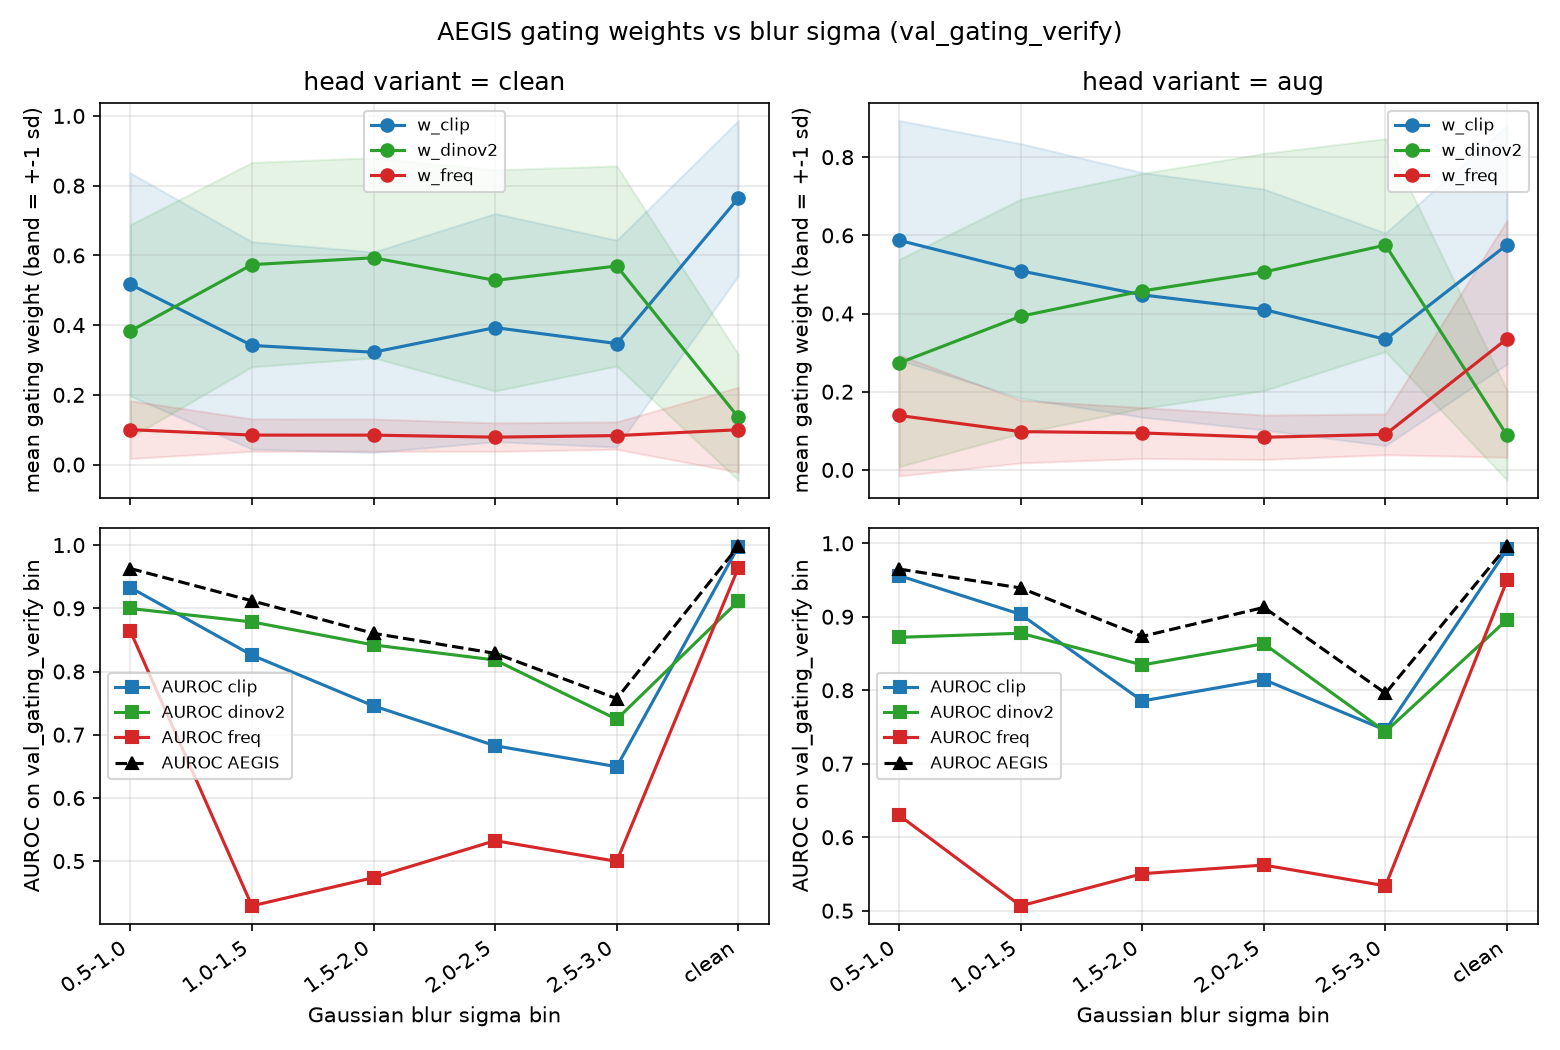

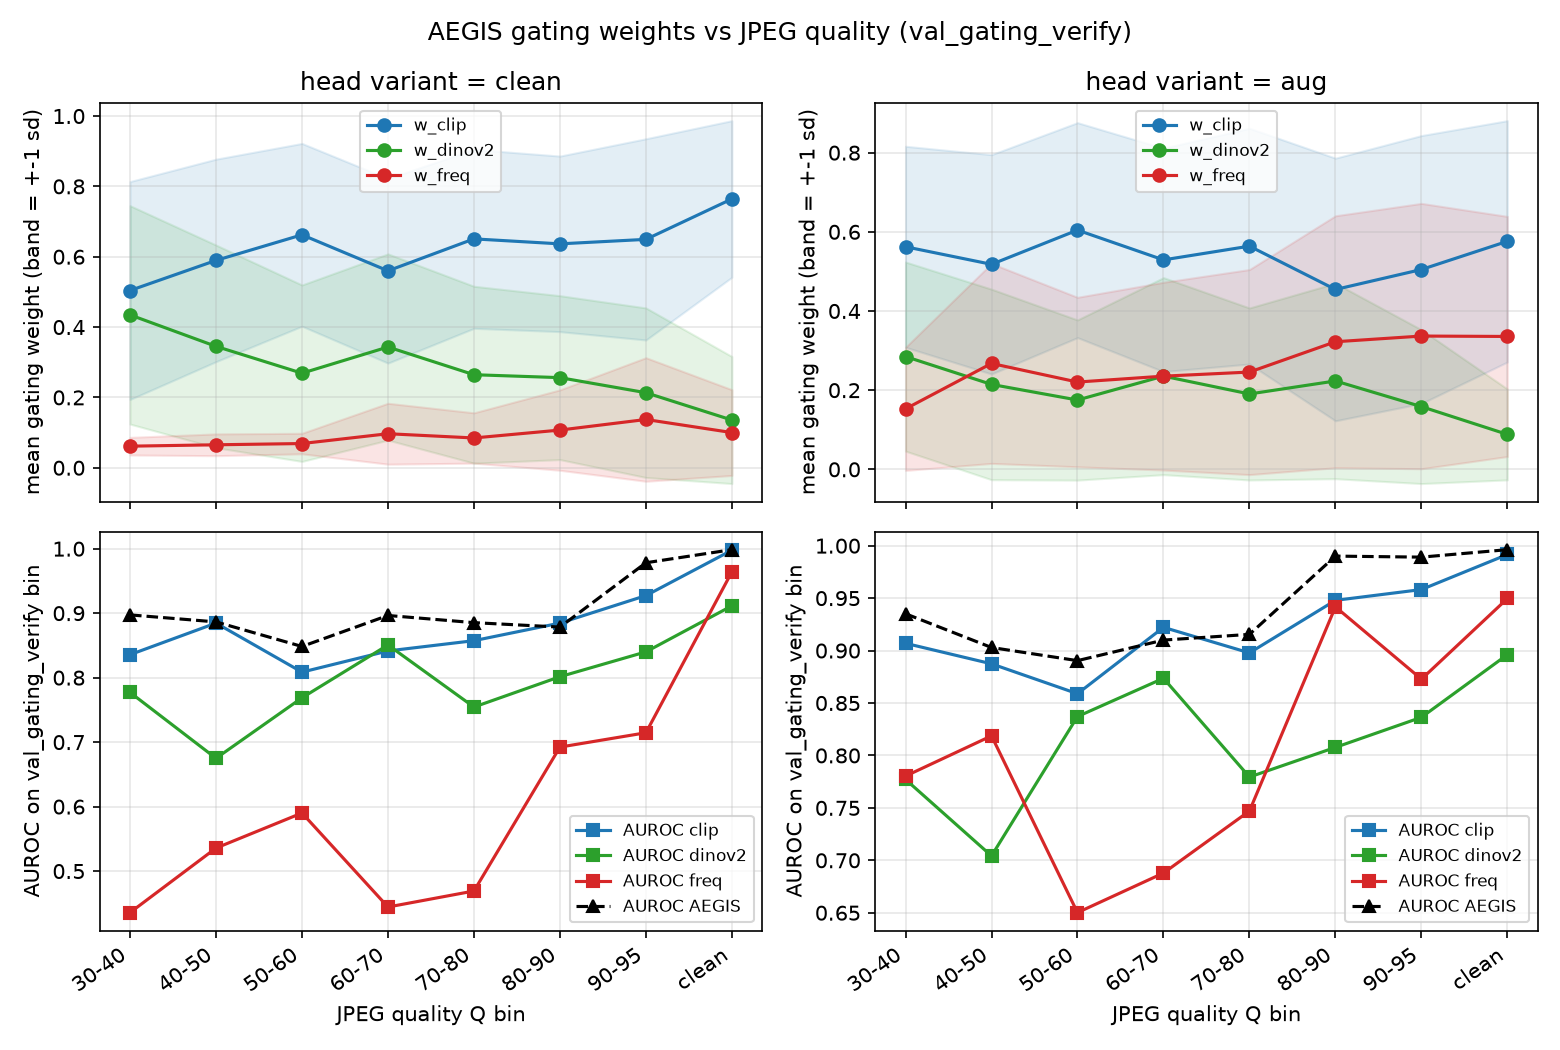

In [7]:
from src.evaluation import weights_analysis as wa
from src.evaluation.predictions import load_predictions
from src.learning.bundle_io import load_split
params = wa.load_degradation_params(MANIFEST)
wrows = []
for hv in HEAD_VARIANTS:
    tg = load_predictions(OUT / "predictions" / f"predictions_{hv}.npz")
    wrows += wa.analyse(cfg, hv, load_split(cfg, "val_gating_fit", hv), load_split(cfg, "val_gating_verify", hv),
                        params, tg)
wa.write_outputs(wrows, OUT)
for f in ("weights_by_blur.png", "weights_by_jpeg.png"):
    if (OUT / f).exists():
        display(Image(filename=str(OUT / f)))

## 5. Xuất hệ thống đã fit cho web demo (kiểm tra trên val_gating_verify, không đọc test)

In [8]:
from src.learning.export import fit_system
system = fit_system(cfg, "aug")
path = ROOT / ("data/demo/serving/aegis_demo_aug.pt" if DEMO else "data/cache/serving/aegis_v3_aug.pt")
path.parent.mkdir(parents=True, exist_ok=True)
system.save(path)
print("saved", path, "| ood_threshold =", round(system.ood_threshold, 4))

2026-11-22 18:33:33,817 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-22 18:33:33,820 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 1.1667, 'dinov2': 1.3626, 'freq': 0.9716}
2026-11-22 18:33:35,225 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.3477 -> 0.2595
2026-11-22 18:33:35,232 | INFO    | aegis.src.learning.export | AEGIS system saved to c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\cache\serving\aegis_v3_aug.pt


saved c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\cache\serving\aegis_v3_aug.pt | ood_threshold = 0.6629
